<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shape: (150, 4) | Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')] 

Best K: 5 | CV accuracy: 0.9667 

Test Accuracy: 0.9333 

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



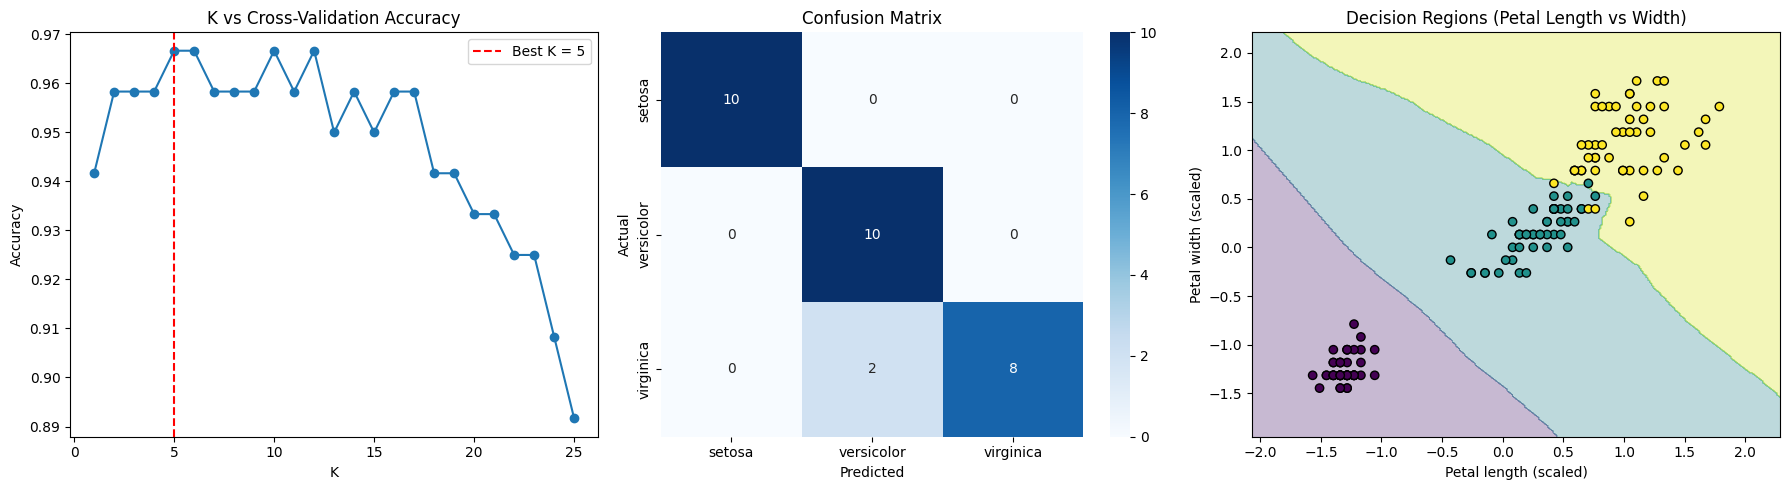

Predicted species: setosa


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# 1. Load dataset
iris = load_iris()
X, y = iris.data, iris.target
print("Shape:", X.shape, "| Classes:", list(iris.target_names), "\n")

# 2. Split and scale
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 3. Find best K using cross-validation
k_values = range(1, 26)
cv_scores = [cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train_s, y_train, cv=5).mean()
             for k in k_values]
best_k = k_values[int(np.argmax(cv_scores))]
print("Best K:", best_k, "| CV accuracy:", round(max(cv_scores), 4), "\n")

# 4. Train final model and evaluate
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)
print("Test Accuracy:", round(accuracy_score(y_test, y_pred), 4), "\n")
print(classification_report(y_test, y_pred, target_names=iris.target_names))

# 5. Graphs
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
ax[0].plot(k_values, cv_scores, marker="o")
ax[0].axvline(best_k, color="r", linestyle="--", label=f"Best K = {best_k}")
ax[0].set_title("K vs Cross-Validation Accuracy")
ax[0].set_xlabel("K"); ax[0].set_ylabel("Accuracy"); ax[0].legend()

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=iris.target_names, yticklabels=iris.target_names, ax=ax[1])
ax[1].set_title("Confusion Matrix"); ax[1].set_xlabel("Predicted"); ax[1].set_ylabel("Actual")

# Decision regions using petal length and petal width
Xp = StandardScaler().fit_transform(X[:, 2:4])
knn2 = KNeighborsClassifier(n_neighbors=best_k).fit(Xp, y)
xx, yy = np.meshgrid(np.linspace(Xp[:, 0].min() - 0.5, Xp[:, 0].max() + 0.5, 300),
                     np.linspace(Xp[:, 1].min() - 0.5, Xp[:, 1].max() + 0.5, 300))
Z = knn2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
ax[2].contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
ax[2].scatter(Xp[:, 0], Xp[:, 1], c=y, edgecolor="k", cmap="viridis")
ax[2].set_title("Decision Regions (Petal Length vs Width)")
ax[2].set_xlabel("Petal length (scaled)"); ax[2].set_ylabel("Petal width (scaled)")
plt.tight_layout()
plt.show()

# 6. Predict a new flower
sample = scaler.transform([[5.1, 3.5, 1.4, 0.2]])
print("Predicted species:", iris.target_names[knn.predict(sample)[0]])